# Lecture 12: Operator Learning

We learn the solution operator of the 1D Burgers equation, $u_0 \mapsto u(\cdot, t)$, with three models trained on a 128-point grid: Fourier neural operator (FNO), CNN and DeepONet.

1. **The data and the operator**: random initial conditions and the solutions at 50 times.
2. **One set of weights on many grids**: evaluate all three models on grids from 32 to 1,024 points.
3. **Inside one Fourier layer**: the Fourier path, the pointwise path and their spectra.
4. **The mode cutoff and sharp fronts**: FNOs with $k_{\max}$ = 4, 8 and 16, and where their error is largest.
5. **DeepONet learns a basis**: trunk functions and POD modes.

The models are trained checkpoints; no training in this notebook. The training code is at the end, for training offline.

In [1]:
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cpu")        # the 1D models are small; complex FFTs on MPS are not fully supported
torch.manual_seed(0)

DATA_DIR = "../data/lecture12"
URL = "https://raw.githubusercontent.com/eecs-ml4sci/eecs-ml4sci.github.io/main/data/lecture12/"
FILES = ["burgers_test_1024.npz", "burgers_train_128.npz", "fno_k16.pt", "fno_k8.pt", "fno_k4.pt", "cnn.pt", "deeponet.pt"]
os.makedirs(DATA_DIR, exist_ok=True)
for f in FILES:
    if not os.path.exists(os.path.join(DATA_DIR, f)):
        print("downloading", f)
        urllib.request.urlretrieve(URL + f, os.path.join(DATA_DIR, f))

### The data

Viscous Burgers equation on the periodic interval $[0, 1)$:

$$u_t + u\,u_x = \nu\, u_{xx}, \qquad \nu = 0.01 .$$

The initial condition $u_0$ is a Gaussian random field with covariance $625(-\Delta + 25 I)^{-2}$, as in Li et al. (2021). A pseudo-spectral solver on 1,024 points (2/3 dealiasing, integrating-factor RK4, $\Delta t = 2\times10^{-4}$) saves $u$ every 0.02 up to $t = 1$, so each sample has 51 snapshots, $u(\cdot, 0) = u_0$ included.

* `burgers_test_1024.npz`: 100 test samples on the full 1,024-point grid, `u[sample, time, x]`.
* `burgers_train_128.npz`: the 1,000 training samples subsampled to 128 points.

The operator we learn maps $u_0$ to the 50 snapshots $u(\cdot, t_j)$, $t_j = 0.02j$, $j = 1, \dots, 50$.

test: (100, 51, 1024)   train: (1000, 51, 128)


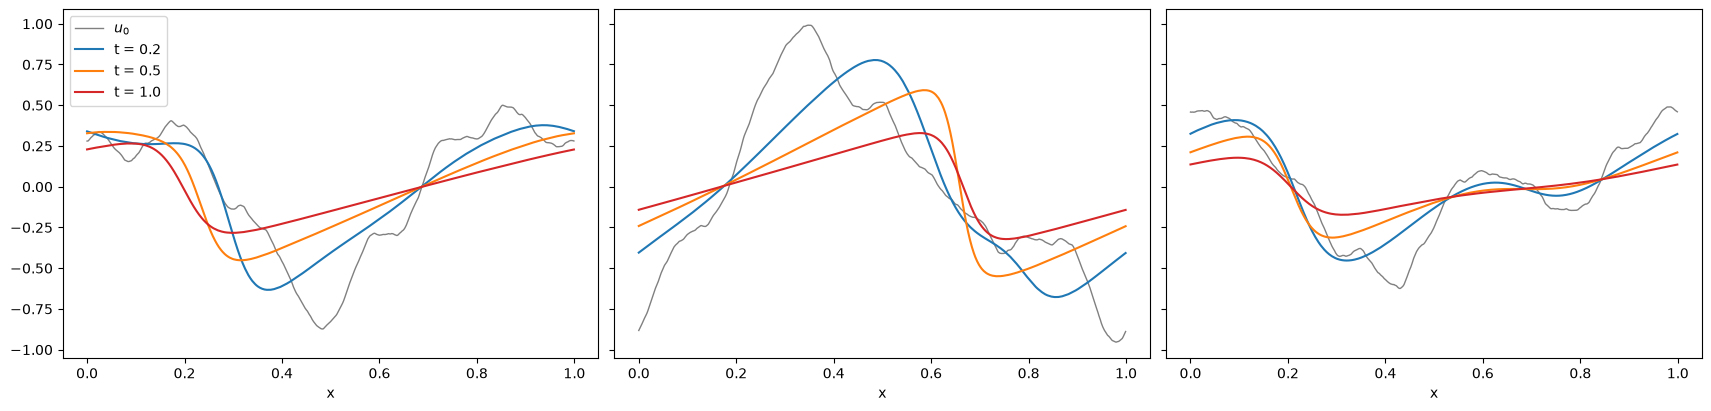

In [2]:
test = np.load(os.path.join(DATA_DIR, "burgers_test_1024.npz"))["u"].astype(np.float32)    # [100, 51, 1024]
train = np.load(os.path.join(DATA_DIR, "burgers_train_128.npz"))["u"].astype(np.float32)   # [1000, 51, 128]
T = 0.02 * np.arange(51)
print("test:", test.shape, "  train:", train.shape)

x = np.arange(1024) / 1024
fig, ax = plt.subplots(1, 3, figsize=(17, 4), layout="constrained", sharey=True)
for a, i in zip(ax, [0, 3, 7]):
    a.plot(x, test[i, 0], color="gray", lw=1, label="$u_0$")
    for j, c in zip([10, 25, 50], ["C0", "C1", "C3"]):
        a.plot(x, test[i, j], color=c, label=f"t = {T[j]:.1f}")
    a.set_xlabel("x")
ax[0].legend(); plt.show()

**What to observe**

* The initial condition is rough: the random field has energy at every wavenumber, falling off like $1/k^2$.
* By $t = 0.2$ the term $u\,u_x$ has steepened the profile into fronts. After that the fronts move and diffusion smooths and decays them.
* The solutions are much smoother than the inputs. Already at $t = 0.2$ the Fourier amplitude at mode 50 is below $10^{-4}$ of the largest, and diffusion keeps lowering it.

### Resampling a periodic function onto another grid

To test a model on $N$ points we need the same function on that grid. For $N < 1024$ we keep the first $N/2$ Fourier modes; for $N > 1024$ we pad with zeros. This is exact for band-limited functions.

In [3]:
def resample(u, N):
    # Fourier resampling along the last axis
    n = u.shape[-1]
    if N == n:
        return u
    uh = np.fft.rfft(u, axis=-1)
    vh = np.zeros(u.shape[:-1] + (N // 2 + 1,), complex)
    m = min(N // 2 + 1, n // 2 + 1)
    vh[..., :m] = uh[..., :m]
    return np.fft.irfft(vh, n=N, axis=-1) * N / n

---
## The models

All three take $u_0$ and return 50 output channels, one per saved time. They were trained on 128 points with the relative $L^2$ loss, Adam (lr $10^{-3}$, cosine schedule, weight decay $10^{-4}$), batch 20, 300 epochs (DeepONet 1,000).

* **FNO**: lift $P$ (inputs $u_0(x)$ and $x$, to 64 channels), 4 Fourier layers with $k_{\max} = 16$, projection $Q$. GELU.
* **CNN**: 10 convolution layers, kernel 7, 64 channels, periodic padding, GELU. Inputs $u_0(x)$ and $x$.
* **DeepONet**: branch MLP on $u_0$ at the 128 training points, trunk MLP on the query point $y$, $p = 64$ basis functions shared by the 50 times.

A Fourier layer computes $v \mapsto \sigma\big(\mathcal F^{-1}(R_k\,(\mathcal F v)_k) + W v\big)$, keeping modes $k \le k_{\max}$. `torch.fft.rfft` returns modes $0, \dots, N/2$; we multiply the first $k_{\max}$ by $R_k$ and set the rest to zero.

In [4]:
class SpectralConv1d(nn.Module):
    # (K v)(x) = F^{-1}( R_k (F v)_k ), modes k < modes; one complex [c_in, c_out] matrix per mode
    def __init__(self, ci, co, modes):
        super().__init__()
        self.modes = modes
        self.w = nn.Parameter(torch.randn(ci, co, modes, dtype=torch.cfloat) / (ci * co))

    def forward(self, v):                                 # v: [B, C, N]
        N = v.shape[-1]
        vh = torch.fft.rfft(v)                            # [B, C, N//2 + 1]
        out = torch.zeros(v.shape[0], self.w.shape[1], N // 2 + 1, dtype=torch.cfloat, device=v.device)
        m = min(self.modes, N // 2 + 1)
        out[:, :, :m] = torch.einsum("bik,iok->bok", vh[:, :, :m], self.w[:, :, :m])
        return torch.fft.irfft(out, n=N)


class FNO1d(nn.Module):
    def __init__(self, modes=16, width=64, layers=4, cin=2, cout=50):
        super().__init__()
        self.P = nn.Conv1d(cin, width, 1)                                         # lift, pointwise
        self.K = nn.ModuleList([SpectralConv1d(width, width, modes) for _ in range(layers)])
        self.W = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(layers)])  # pointwise path
        self.Q1, self.Q2 = nn.Conv1d(width, 128, 1), nn.Conv1d(128, cout, 1)      # project, pointwise

    def forward(self, a):
        v = self.P(a)
        for i, (K, W) in enumerate(zip(self.K, self.W)):
            v = K(v) + W(v)
            if i < len(self.K) - 1:
                v = F.gelu(v)
        return self.Q2(F.gelu(self.Q1(v)))


class CNN1d(nn.Module):
    def __init__(self, width=64, layers=10, k=7, cin=2, cout=50):
        super().__init__()
        conv = lambda i, o: nn.Conv1d(i, o, k, padding=k // 2, padding_mode="circular")
        L = [conv(cin, width), nn.GELU()]
        for _ in range(layers - 2):
            L += [conv(width, width), nn.GELU()]
        self.net = nn.Sequential(*L, conv(width, cout))

    def forward(self, a):
        return self.net(a)


class DeepONet(nn.Module):
    def __init__(self, m=128, p=64, cout=50, h=256):
        super().__init__()
        self.p, self.cout = p, cout
        mlp = lambda i, o: nn.Sequential(nn.Linear(i, h), nn.GELU(), nn.Linear(h, h), nn.GELU(),
                                         nn.Linear(h, h), nn.GELU(), nn.Linear(h, o))
        self.branch = mlp(m, p * cout)                    # u0 at m sensors -> p coefficients per output time
        self.trunk = mlp(1, p)                            # query point y -> p basis functions
        self.bias = nn.Parameter(torch.zeros(cout))

    def basis(self, y):                                   # y: [N] -> tau_k(y): [N, p]
        return self.trunk(y[:, None])

    def forward(self, u0_sensors, y):                     # [B, m], [N] -> [B, cout, N]
        b = self.branch(u0_sensors).view(-1, self.cout, self.p)
        return torch.einsum("bcp,np->bcn", b, self.basis(y)) + self.bias[None, :, None]


def load(model, name):
    model.load_state_dict(torch.load(os.path.join(DATA_DIR, name), map_location="cpu"))
    return model.to(device).eval()

fno = load(FNO1d(modes=16), "fno_k16.pt")
cnn = load(CNN1d(), "cnn.pt")
don = load(DeepONet(), "deeponet.pt")
for name, m in [("FNO", fno), ("CNN", cnn), ("DeepONet", don)]:
    print(f"{name:9s} {sum(p.numel() for p in m.parameters()):>9,d} parameters (a complex weight counts once)")

FNO         293,746 parameters (a complex weight counts once)
CNN         253,298 parameters (a complex weight counts once)
DeepONet  1,135,602 parameters (a complex weight counts once)


In [5]:
def inputs(u0):
    # [B, N] -> [B, 2, N]: u0(x) and the coordinate x in [0, 1)
    u0 = torch.as_tensor(u0, dtype=torch.float32)
    xN = torch.arange(u0.shape[-1]) / u0.shape[-1]
    return torch.stack([u0, xN.expand_as(u0)], 1).to(device)

@torch.no_grad()
def predict(model, u, N):
    # u: [B, 51, 1024] reference data; returns predictions [B, 50, N] on the N-point grid
    uN = resample(u, N)
    if isinstance(model, DeepONet):
        sensors = torch.as_tensor(resample(u[:, 0], 128), dtype=torch.float32)   # input on the 128 training points
        return model(sensors, torch.arange(N) / N).numpy()
    return model(inputs(uN[:, 0])).cpu().numpy()

def rel_l2(pred, ref):
    # relative L2 error of each sample over all output times and points
    d = (pred - ref).reshape(len(ref), -1); r = ref.reshape(len(ref), -1)
    return np.linalg.norm(d, axis=1) / np.linalg.norm(r, axis=1)

---
## Part 2: One set of weights on many grids

Each model was trained on 128 points. We evaluate it on $N$ = 32 to 1,024 points without retraining. The FNO and the CNN take the input on the test grid. The DeepONet takes its input on its 128 sensors and returns the output on the test grid.

N =    32   FNO: 0.0072   CNN: 0.9029   DeepONet: 0.0567
N =    64   FNO: 0.0050   CNN: 0.5470   DeepONet: 0.0567
N =   128   FNO: 0.0050   CNN: 0.0749   DeepONet: 0.0567
N =   256   FNO: 0.0050   CNN: 0.4336   DeepONet: 0.0568
N =   512   FNO: 0.0050   CNN: 0.5882   DeepONet: 0.0569
N =  1024   FNO: 0.0050   CNN: 0.6473   DeepONet: 0.0569


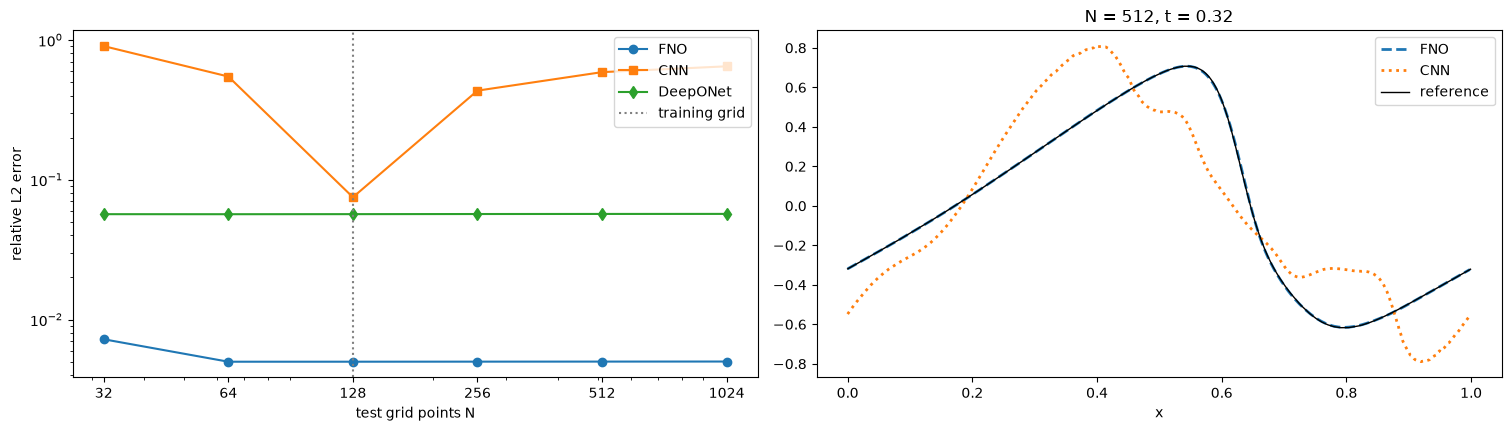

N =   512   FNO: 0.0050   CNN: 0.5882   DeepONet: 0.0569


N =  1024   FNO: 0.0050   CNN: 0.6473   DeepONet: 0.0569


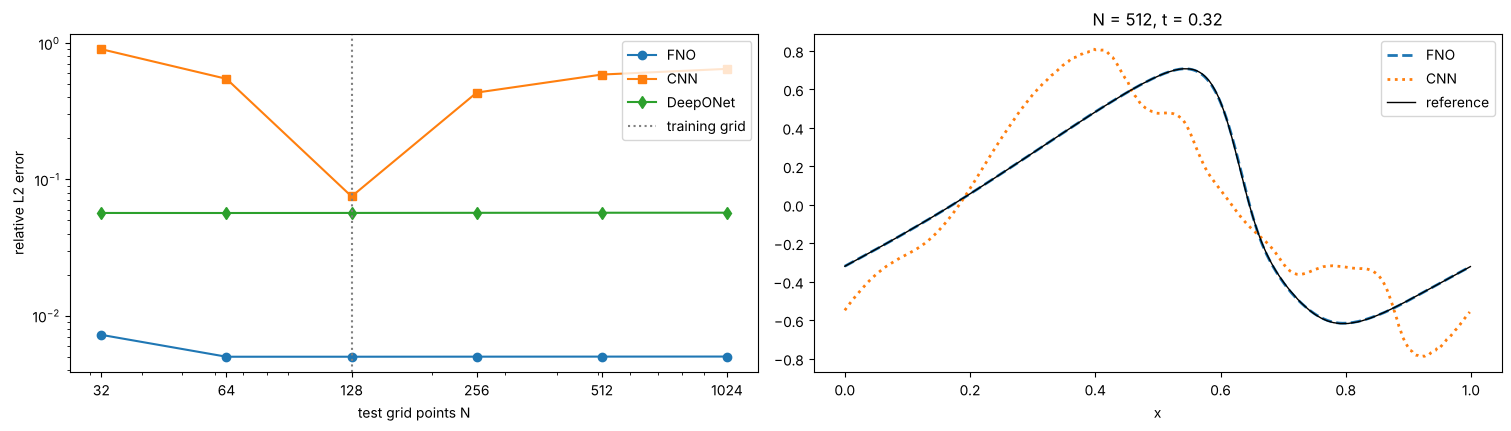

In [6]:
Ns = [32, 64, 128, 256, 512, 1024]
errors = {"FNO": [], "CNN": [], "DeepONet": []}
for N in Ns:
    ref = resample(test[:, 1:], N)
    for name, m in [("FNO", fno), ("CNN", cnn), ("DeepONet", don)]:
        errors[name].append(rel_l2(predict(m, test, N), ref).mean())
    print(f"N = {N:5d}   " + "   ".join(f"{k}: {v[-1]:.4f}" for k, v in errors.items()))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), layout="constrained")
for (name, e), mk in zip(errors.items(), "osd"):
    ax[0].plot(Ns, e, marker=mk, label=name)
ax[0].axvline(128, color="gray", ls=":", label="training grid")
ax[0].set(xscale="log", yscale="log", xlabel="test grid points N", ylabel="relative L2 error")
ax[0].set_xticks(Ns); ax[0].set_xticklabels(Ns); ax[0].legend()

i, j, N = 3, 15, 512                                       # sample, output time t = 0.32, grid
for name, m, st in [("FNO", fno, "--"), ("CNN", cnn, ":")]:
    ax[1].plot(np.arange(N) / N, predict(m, test[i:i + 1], N)[0, j], st, lw=2, label=name)
ax[1].plot(x, test[i, j + 1], "k", lw=1, label="reference")
ax[1].set(xlabel="x", title=f"N = {N}, t = {T[j + 1]:.2f}"); ax[1].legend(); plt.show()

**What to observe**

* The CNN has its lowest error on the training grid. On every other grid the error is larger: its kernels are stencils for a cell size of 1/128.
* The FNO error is about the same from 64 to 1,024 points. At 32 points it is slightly higher: the rough input is under-resolved on that grid.
* No model gets more accurate on a finer grid. The FNO returns a function that matches the reference about as well as on 128 points.
* These outputs are smooth, so a finer grid adds almost no new frequencies. Zero-shot transfer is much harder when it does (Sakarvadia et al. 2026; Exercise 2).

---
## Part 3: Inside one Fourier layer

We follow one test input through the first layer of the FNO on 1,024 points and look at one of the 64 channels: the lifted input $v$, the Fourier path $\mathcal K v$, the pointwise path $W v$, and the output $\sigma(\mathcal K v + W v)$.

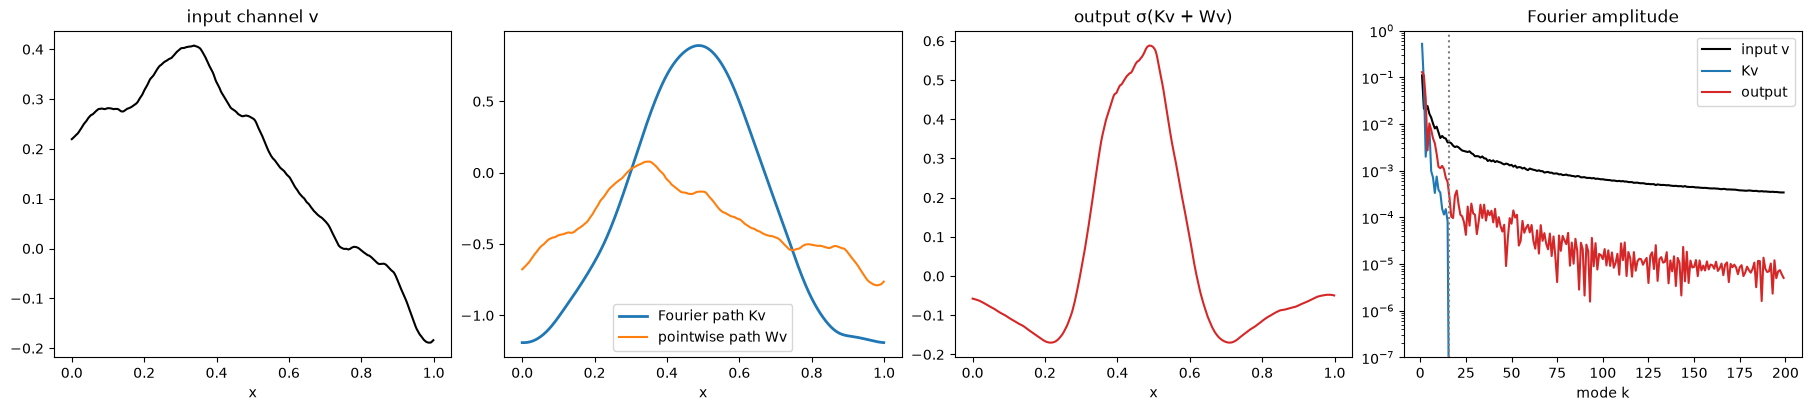

In [7]:
with torch.no_grad():
    v = fno.P(inputs(test[3:4, 0]))
    Kv, Wv = fno.K[0](v), fno.W[0](v)
    out = F.gelu(Kv + Wv)
c = int(Kv[0].std(1).argmax())                           # the channel with the largest Fourier-path output
v, Kv, Wv, out = [t[0, c].numpy() for t in (v, Kv, Wv, out)]

fig, ax = plt.subplots(1, 4, figsize=(18, 4), layout="constrained")
ax[0].plot(x, v, "k"); ax[0].set_title("input channel v")
ax[1].plot(x, Kv, lw=2, label="Fourier path Kv"); ax[1].plot(x, Wv, label="pointwise path Wv"); ax[1].legend()
ax[2].plot(x, out, "C3"); ax[2].set_title("output σ(Kv + Wv)")
k = np.arange(513)
for f, lab, col in [(v, "input v", "k"), (Kv, "Kv", "C0"), (out, "output", "C3")]:
    ax[3].semilogy(k[1:200], np.abs(np.fft.rfft(f))[1:200] / 1024, col, label=lab)
ax[3].axvline(16, color="gray", ls=":"); ax[3].set(xlabel="mode k", ylim=(1e-7, 1), title="Fourier amplitude")
ax[3].legend()
for a in ax[:3]:
    a.set_xlabel("x")
plt.show()

**What to observe**

* The Fourier path is smooth: its spectrum stops at $k_{\max} = 16$.
* The pointwise path keeps the roughness of the input at every mode.
* The output has energy far above $k_{\max}$. It comes from $W v$ and from GELU, which multiplies modes together at each point (Lecture 3: modes $k$ and $k'$ create $k + k'$).

---
## Part 4: The mode cutoff and sharp fronts

Three FNOs that differ only in $k_{\max}$ (4, 8 and 16), trained the same way. We compare their errors over time and where along $x$ the error is largest.

k_max =  4: relative L2 error 0.0148,  97,138 parameters
k_max =  8: relative L2 error 0.0070,  162,674 parameters
k_max = 16: relative L2 error 0.0050,  293,746 parameters


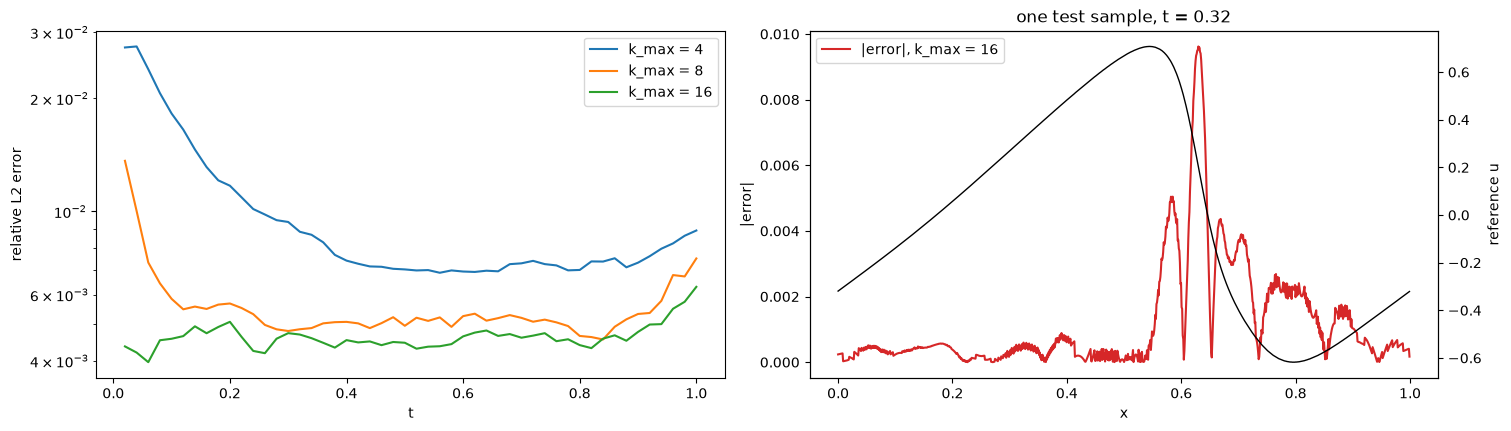

In [8]:
fnos = {k: load(FNO1d(modes=k), f"fno_k{k}.pt") for k in (4, 8, 16)}
ref = test[:, 1:]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), layout="constrained")
for k, m in fnos.items():
    p = predict(m, test, 1024)
    err_t = np.linalg.norm(p - ref, axis=2) / np.linalg.norm(ref, axis=2)        # [samples, times]
    ax[0].plot(T[1:], err_t.mean(0), label=f"k_max = {k}")
    print(f"k_max = {k:2d}: relative L2 error {rel_l2(p, ref).mean():.4f},  {sum(q.numel() for q in m.parameters()):,} parameters")
    if k == 16:
        p16 = p
ax[0].set(xlabel="t", ylabel="relative L2 error", yscale="log"); ax[0].legend()

i, j = 3, 15
ax[1].plot(x, np.abs(p16[i, j] - ref[i, j]), "C3", label="|error|, k_max = 16")
a2 = ax[1].twinx(); a2.plot(x, ref[i, j], "k", lw=1); a2.set_ylabel("reference u", color="k")
ax[1].set(xlabel="x", ylabel="|error|", title=f"one test sample, t = {T[j + 1]:.2f}"); ax[1].legend(loc="upper left")
plt.show()

**What to observe**

* The error falls as $k_{\max}$ grows. Going from 4 to 8 modes helps more than going from 8 to 16.
* With 4 and 8 modes the error is largest at early times, when the solution still carries the small-scale roughness of $u_0$. With 16 modes it is about the same at all times.
* Along $x$, the error is largest at and just behind the front and small where the solution is smooth (slide on PDEBench and sharp fronts).

---
## Part 5: DeepONet learns a basis

The DeepONet output at time $t_j$ is $\sum_k b_{jk}(u_0)\,\tau_k(y) + b_{0j}$: a combination of $p = 64$ trunk functions $\tau_k$. We compare the space these functions span with the POD modes of the training outputs (Lecture 4): the right singular vectors of the mean-subtracted outputs at $t = 1$.

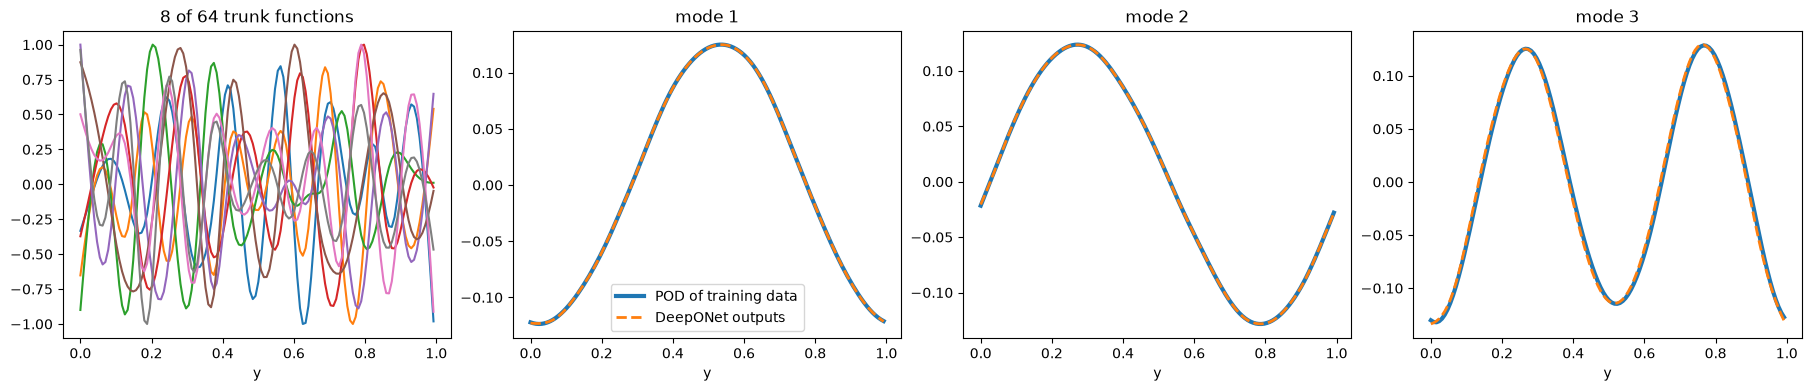

fraction of variance in the first 6 POD modes: [0.402 0.387 0.073 0.072 0.022 0.021]


In [9]:
y = torch.arange(128) / 128
with torch.no_grad():
    tau = don.basis(y).numpy()                                                     # [128, p]
    pred_train = don(torch.as_tensor(train[:, 0]), y).numpy()[:, -1]                # DeepONet outputs at t = 1
U, S, Vt = np.linalg.svd(train[:, -1] - train[:, -1].mean(0), full_matrices=False)
_, _, Vd = np.linalg.svd(pred_train - pred_train.mean(0), full_matrices=False)

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8), layout="constrained")
for kk in range(8):
    ax[0].plot(y, tau[:, kk] / np.abs(tau[:, kk]).max())
ax[0].set_title("8 of 64 trunk functions")
for n in range(3):
    s = np.sign(Vd[n] @ Vt[n])
    ax[n + 1].plot(y, Vt[n], lw=3, label="POD of training data")
    ax[n + 1].plot(y, s * Vd[n], "--", lw=2, label="DeepONet outputs")
    ax[n + 1].set_title(f"mode {n + 1}")
ax[1].legend()
for a in ax:
    a.set_xlabel("y")
plt.show()
print("fraction of variance in the first 6 POD modes:", np.round(S[:6] ** 2 / (S ** 2).sum(), 3))

**What to observe**

* The trunk functions are smooth but have no natural order.
* The leading modes of the DeepONet outputs match the POD modes of the data. The trunk has learned approximately the same subspace that POD finds directly.
* The POD modes come in pairs of sines and cosines with similar variance: the data are statistically invariant to shifts in $x$, so the best basis is close to a Fourier basis (Lecture 4).

---
## Exercises

1. **Upsampling baseline.** Colagrande et al. (2026) compare two ways to get an FNO prediction on a fine grid: run the FNO on the fine grid, or run it on its training grid and upsample the output by Fourier zero-padding (`resample`). Compute both for $N$ = 256, 512 and 1,024. Which is more accurate here? Why might the answer differ for Darcy flow?
2. **New frequencies on a finer grid.** Generate test inputs with more small-scale content, e.g. with covariance $625(-\Delta + 25 I)^{-1.5}$ (use the solver below with 100 samples). Evaluate the FNO trained on 128 points at 128 and 1,024 points. Does its error still stay flat? Look at the spectra of the predictions.
3. **Modes at inference.** In the $k_{\max} = 16$ FNO, set $R_k = 0$ for $k \ge k'$ in every layer (copy the model first) and plot the error against $k'$. Compare with the FNOs trained with $k_{\max}$ = 4 and 8. Why is truncating a trained model worse than training with fewer modes?
4. **Offline: train on a coarser grid.** Using the training code below on HPC3, train the FNO on 64 points and evaluate it on 64 to 1,024 points. Then train it on a mix of 64- and 128-point batches (multi-resolution training, Sakarvadia et al. 2026). Compare the error curves.

In [10]:
# Exercise 1 starter
def upsampled_prediction(model, u, N, N_train=128):
    # TODO: predict on the N_train grid, then Fourier-resample the output to N points
    raise NotImplementedError

In [11]:
# Exercise 2 starter: the solver used to make the data
def burgers_solve(u0, nu=0.01, T_end=1.0, nsave=50, dt=2e-4):
    # u0: [B, N] on a periodic grid of [0, 1). Pseudo-spectral, 2/3 dealiasing, integrating-factor RK4
    B, N = u0.shape
    k = 2 * np.pi * np.fft.rfftfreq(N, d=1.0 / N)
    dealias = (np.fft.rfftfreq(N, d=1.0 / N) < N / 3).astype(float)
    E1, E2 = np.exp(-nu * k ** 2 * dt / 2), np.exp(-nu * k ** 2 * dt)
    NL = lambda uh: -0.5j * k * np.fft.rfft(np.fft.irfft(uh, n=N) ** 2) * dealias
    uh = np.fft.rfft(u0); steps = int(round(T_end / dt)); every = steps // nsave
    out = [u0]
    for n in range(1, steps + 1):
        a = NL(uh); b = NL(E1 * (uh + dt / 2 * a)); c = NL(E1 * uh + dt / 2 * b); d = NL(E2 * uh + dt * E1 * c)
        uh = E2 * uh + dt / 6 * (E2 * a + 2 * E1 * (b + c) + d)
        if n % every == 0:
            out.append(np.fft.irfft(uh, n=N))
    return np.stack(out, 1)                                # [B, nsave + 1, N]

def grf(B, N=1024, power=2.0, seed=0):
    # Gaussian random field with covariance 625 (-Lap + 25 I)^(-power)
    rng = np.random.default_rng(seed)
    kk = 2 * np.pi * np.fft.rfftfreq(N, d=1.0 / N)
    sig = 25.0 / (kk ** 2 + 25.0) ** (power / 2)          # standard deviation of each Fourier coefficient
    c = (rng.standard_normal((B, len(kk))) + 1j * rng.standard_normal((B, len(kk)))) * sig
    c[:, 0] = 0
    return np.fft.irfft(c, n=N) * N / np.sqrt(2)

# u_new = burgers_solve(grf(100, power=1.5))    # about 30 s on a laptop for 100 samples

In [12]:
# Training code (used for the checkpoints; run offline, e.g. on one HPC3 GPU)
def train_model(model, train_u, epochs=300, lr=1e-3, batch=20, deeponet=False):
    # train_u: [n, 51, N] on an N-point grid
    data = torch.as_tensor(train_u, dtype=torch.float32)
    opt = torch.optim.Adam(model.parameters(), lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    yN = torch.arange(data.shape[-1]) / data.shape[-1]
    for ep in range(epochs):
        for idx in torch.randperm(len(data)).split(batch):
            b = data[idx]
            p = model(b[:, 0], yN) if deeponet else model(inputs(b[:, 0]))
            loss = (torch.linalg.norm((p - b[:, 1:]).flatten(1), dim=1) / torch.linalg.norm(b[:, 1:].flatten(1), dim=1)).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
    return model

# model = train_model(FNO1d(modes=16), train)